# Рекомендательная система Goodreads: сравнение пяти методов

Источник: [UCSD Book Graph — Goodreads Fantasy & Paranormal](https://sites.google.com/eng.ucsd.edu/ucsdbookgraph/home). Рекомендуем **книги** по истории оценок пользователей. rating — явная оценка 1–5; релевантность для топ-10: rating >= 4. Что в целом логично, что начиная с 4х оценка значит "хорошо"

Пять методов: ItemKNN, explicit ALS, EASE, FM с метапризнаками и TemporalTargetALS с изменённым целевым сигналом. Главная метрика — NDCG@10, дополнительная — Recall@10.



Данные — Goodreads Fantasy & Paranormal, отзывы и информация о книгах. Источник указан в DATA.md.

Для запуска нужно установить зависимости из requirements.txt и выполнить experiments.ipynb из корня hw1. Подготовка данных реализована в utils/data.py.

In [12]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits

from models import EASE, ExplicitALS, FactorizationMachine, ItemKNN, TemporalTargetALS
from utils.data import FMFeatures, encode_and_split, matrix, prepare_data
from utils.metrics import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
threadpool_limits(limits=1)

project_dir = Path.cwd()
data_dir = project_dir / "data"

## 1. Источник, взаимодействия и выборка

Исходные данные — два архива Goodreads: goodreads_reviews_fantasy_paranormal.json.gz с отзывами и goodreads_books_fantasy_paranormal.json.gz с информацией о книгах. В отзывах используются идентификаторы пользователей и книг, оценки и даты. Из метаданных берём название, авторов, язык и год публикации.

Для эксперимента читаем первые 900 000 отзывов, удаляем записи с некорректными оценками и датами, а для повторных оценок одной книги пользователем оставляем последнюю. Затем выбираем до 2500 популярных книг и 12 000 активных пользователей. Оставляем пользователей минимум с 5 взаимодействиями и книги минимум с 10. Итоговую выборку ограничиваем 180 000 оценками с помощью детерминированного хеширования.

Обработка данных реализована в utils/data.py. Для воспроизводимости используется seed = 42.


In [4]:
from utils.data import BOOK_FILE, REVIEW_FILE, download

for filename in (REVIEW_FILE, BOOK_FILE):
    archive_path = download(filename, data_dir)
    print(filename, f'{archive_path.stat().st_size / 1024 ** 2:.1f} MiB (gzip)')

scan_limit = 900_000
started = time.perf_counter()
raw, book_meta = prepare_data(
    folder=data_dir,
    scan_limit=scan_limit,
    max_items=2500,
    max_users=12000,
    max_events=180_000,
    min_user=5,
    min_item=10,
)
print('Rows scanned (upper bound):', scan_limit)
print(f'Preparation: {time.perf_counter() - started:.1f} sec')
print('Interactions after filtering:', len(raw))
print('Users:', raw.user_id.nunique())
print('Books:', raw.book_id.nunique())
print('Period:', raw.timestamp.min(), '—', raw.timestamp.max())
assert len(raw) >= 100_000
assert raw.user_id.nunique() >= 1000
assert raw.book_id.nunique() >= 1000
display(raw.head())
display(book_meta.head())

goodreads_reviews_fantasy_paranormal.json.gz 1200.8 MiB (gzip)
goodreads_books_fantasy_paranormal.json.gz 265.9 MiB (gzip)
Rows scanned (upper bound): 900000
Preparation: 85.9 sec
Interactions after filtering: 176102
Users: 10884
Books: 2485
Period: 2006-05-26 07:00:00+00:00 — 2017-10-28 02:29:04+00:00


,user_id,book_id,rating,timestamp
0,a4a7ad405ec20fa3d527cde580e8e65b,49852,5,2006-05-26 07:00:00+00:00
1,8842281e1d1347389f2ab93d60773d4d,2,5,2006-08-29 18:20:05+00:00
2,8842281e1d1347389f2ab93d60773d4d,6,5,2006-08-29 18:20:10+00:00
3,6a22bb07026c9bb6f17922d2d61116ae,5907,5,2007-02-06 18:02:36+00:00
4,fd5c20e5ff679c72eb2e9f620d6ddabd,69136,5,2007-02-25 22:54:15+00:00


,title,author,language,year
book_id,,,,
1,Harry Potter and the Half-Blood Prince (Harry ...,1077326,eng,2006.0
10025305,"Clockwork Prince (The Infernal Devices, #2)",150038,eng,2011.0
10031259,"The Emperor's Edge (The Emperor's Edge, #1)",4512224,eng,2010.0
10048874,"Dearly, Departed (Gone With the Respiration, #1)",3353667,en-US,2011.0
10079321,"The Magician King (The Magicians, #2)",142270,en-US,2011.0


## 2. EDA и очистка

Проверяем пропуски, дубликаты (user_id, book_id), активность пользователей, популярность книг, распределение оценок, разреженность и метаданные. Дубликаты удалены при подготовке; неизвестный publication_year оставлен NaN, а не нулём. Язык извлекается из оригинального language_code. Для FM пропущенные категориальные значения выделяются в категорию unknown год переводится в десятилетие.


Missing review values:


,missing
user_id,0
book_id,0
rating,0
timestamp,0


Duplicate user-book pairs: 0
Missing metadata values:


,missing
title,0
author,0
language,0
year,280


Sparsity: 0.99349


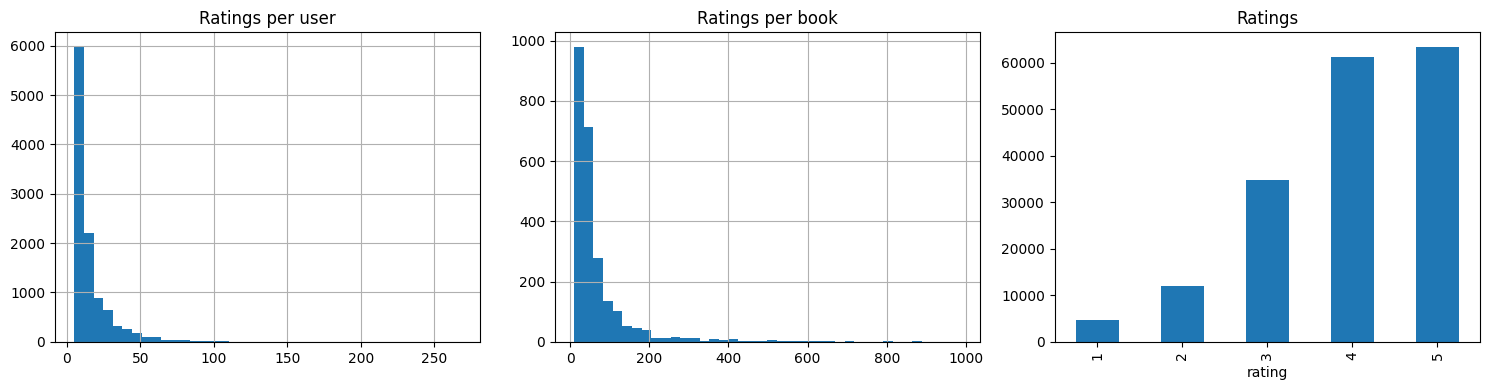

Languages (including unknown):


,count
language,
eng,1843
en-US,483
unknown,74
en-GB,57
en-CA,24
spa,2
ger,2


Publication years (known only):


,year
count,2205.000000
mean,2010.257143
std,5.228933
min,1973.000000
25%,2008.000000
50%,2011.000000
75%,2014.000000
max,2017.000000


Share of missing years: 0.113


In [5]:
print('Missing review values:')
display(raw.isna().sum().to_frame('missing'))
print('Duplicate user-book pairs:', raw.duplicated(['user_id', 'book_id']).sum())
print('Missing metadata values:')
display(book_meta.isna().sum().to_frame('missing'))
print('Sparsity:', round(1 - len(raw) / (raw.user_id.nunique() * raw.book_id.nunique()), 5))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
raw.groupby('user_id').size().hist(ax=axes[0], bins=40)
axes[0].set_title('Ratings per user')
raw.groupby('book_id').size().hist(ax=axes[1], bins=40)
axes[1].set_title('Ratings per book')
raw.rating.value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_title('Ratings')
plt.tight_layout()
plt.show()

print('Languages (including unknown):')
display(book_meta['language'].value_counts().head(10))
print('Publication years (known only):')
display(book_meta['year'].describe())
print('Share of missing years:', round(book_meta.year.isna().mean(), 3))

## 3. Temporal split, кандидаты и метрики

**Разбиение по каждому пользователю:** последнее событие по timestamp — test, предпоследнее — validation, остальные — train. События, чьи книги отсутствуют в train, удаляются из validation/test (**warm-start item**). Пользователи с историей train оцениваются даже тогда, когда их отложенная оценка оказалась нерелевантной (1–3). Новых пользователей и книги в этом offline-протоколе не оцениваем.

Набор пользователей определяем только по train, до обращения к меткам validation/test: берём до 500 ID фиксированным генератором SEED=42. Пользователи без релевантных книг в данном отложенном срезе получают 0 для NDCG@10 и Recall@10, а не исключаются из среднего.

Все методы ранжируют весь каталог книг из обучающей истории. Уже известные пользователю книги маскируются (-inf). Для каждого пользователя кандидаты и релевантность одинаковы у всех моделей. При test модель обучается на train+validation и исключает все объекты из этой истории.

Для пользователя `u` множество релевантных книг в отложенном срезе: `R_u = {i: rating_ui >= 4}`. Обозначим `P_u@10` — первые 10 непосмотренных книг рекомендаций. Выбираем **NDCG@10** как основную метрику, поскольку важен порядок попаданий в списке:

$$
\mathrm{DCG@10}(u)=\sum_{j=1}^{10}\frac{\mathbf{1}[P_{u,j}\in R_u]}{\log_2(j+1)},\qquad
\mathrm{NDCG@10}(u)=\frac{\mathrm{DCG@10}(u)}{\mathrm{IDCG@10}(u)}.
$$

Для `R_u = ∅` устанавливаем `NDCG@10 = 0`. Дополнительная метрика — доля найденных релевантных объектов:

$$
\mathrm{Recall@10}(u)=\frac{|P_u@10\cap R_u|}{|R_u|},\qquad
\mathrm{Recall@10}(u)=0\text{ при }R_u=\varnothing.
$$

Обе метрики усредняются **по всем фиксированным пользователям**, а не только по имеющим положительную оценку. Per-user split не является общим глобальным временным cutoff и допускает обучение на событиях других пользователей, произошедших позже отдельного пользовательского test — это ограничение схемы.


In [6]:
train, val, test, user_map, item_map = encode_and_split(raw)
n_users = len(user_map)
n_items = len(item_map)
assert train.u.max() < n_users and train.i.max() < n_items
assert train.groupby('u').size().min() >= 1
assert train.timestamp.notna().all()
assert not set(zip(train.u, train.i)) & set(zip(val.u, val.i))
assert not set(zip(train.u, train.i)) & set(zip(test.u, test.i))

eligible_users = np.sort(train.u.unique())
selected_users = np.random.default_rng(SEED).choice(
    eligible_users, size=min(500, len(eligible_users)), replace=False
).tolist()
assert selected_users

print('Train / validation / test:', len(train), len(val), len(test))
print('Encoded users / books:', n_users, n_items)
print('Selected train-only cohort:', len(selected_users))
print('Users with validation rows:', val.u.nunique())
print('Users with test rows:', test.u.nunique())
print('Positive validation rows:', int((val.rating >= 4).sum()))
print('Positive test rows:', int((test.rating >= 4).sum()))
print('Train catalog size:', train.i.nunique())
print('Sampled evaluated IDs:', selected_users[:10])

Train / validation / test: 154334 10884 10884
Encoded users / books: 10884 2485
Selected train-only cohort: 500
Users with validation rows: 10884
Users with test rows: 10884
Positive validation rows: 7634
Positive test rows: 7518
Train catalog size: 2485
Sampled evaluated IDs: [10636, 9622, 3886, 1235, 4286, 3011, 6266, 7828, 9018, 9699]


## 4. Модели и формулы

Все пять реализаций находятся в отдельных файлах models/. Функции обучаются без готовых библиотек рекомендательных алгоритмов. Везде u — пользователь, i — книга, `r_ui ∈ {1,2,3,4,5}`, `X` — бинарная матрица взаимодействий с `rating >= 4`.

**1. ItemKNN.** Косинусная близость столбцов бинарной матрицы с аддитивным shrinkage; для каждой книги оставляем k ближайших соседей, диагональ обнуляем:

$$
s_{ij}=\frac{X_{:i}^{\top}X_{:j}}{\|X_{:i}\|_2\|X_{:j}\|_2+\beta},\qquad
\hat s(u,i)=\sum_{j\in I_u^{+}}s_{ji}.
$$

Подбираем число соседей `k ∈ {40,100}` при `β=20`.

**2. Explicit ALS.** Факторизуем матрицу наблюдаемых явных оценок (не заменяем отсутствующие нулями). Для `Ω` — множества известных пар:

$$
\min_{P,Q}\ \sum_{(u,i)\in\Omega}(r_{ui}-p_u^\top q_i)^2
+\lambda\sum_u |I_u|\|p_u\|_2^2
+\lambda\sum_i |U_i|\|q_i\|_2^2,
\qquad \hat r_{ui}=p_u^\top q_i.
$$

В коде чередуем решения нормальных уравнений по строкам и столцам. Подбираем размер факторов {12,24} при regularization=0.5, iterations=4.

**3. EASE.** Линейное item-item восстановление бинарных взаимодействий, с ограничением нулевой диагонали:

$$
\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,\quad
\operatorname{diag}(B)=0.\quad
G=X^\top X+\lambda I,\quad P=G^{-1},\quad
B_{ij}=\begin{cases}-P_{ij}/P_{jj},&i\ne j,\\0,&i=j.\end{cases}
$$

Подбираем `regularization ∈ {100,400}`. Рекомендации: строка `X_u B`.

**4. FM второго порядка.** Признаки — one-hot user ID и book ID плюс автор, язык, десятилетие публикации. Они доступны из справочной карточки книги независимо от отложенных оценок (при этом ретроспективный снимок метаданных ограничивает историческую корректность):

$$
\hat r(x)=w_0+\sum_j w_j x_j
+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.
$$

Оптимизируем квадрат ошибки по явным рейтингам пакетным Adam; подбираем число факторов `{8,16}` при learning_rate=0.01, regularization=0.001, epochs=3. 

**5. TemporalTargetALS — собственный таргет.** Для возраста оценки `a_ui` в годах относительно самой поздней даты *обучающего среза* и `γ > 0`:

$$
t_{ui}=1+(r_{ui}-1)e^{-\gamma a_{ui}}.
$$

Недавние оценки сохраняют исходный уровень, старые постепенно приближаются к нейтральному базовому значению 1. Изменяется целевой сигнал t_ui, а не confidence или вес ошибки. В ExplicitALS заменяем наблюдаемое r_ui на t_ui, сохраняя остальную оптимизацию. Гипотеза: давно добавленные книги хуже отражают текущий вкус; сравниваем с обычным ALS на одинаковом holdout. Подбираем decay ∈ {0.15,0.6} при factors=12, regularization=0.5, iterations=4.


In [7]:
def train_model(name, params, frame, include_metadata=True):
    ratings = matrix(frame, n_users, n_items)
    positive_frame = frame[frame.rating >= 4]
    positives = matrix(positive_frame, n_users, n_items, binary=True)

    if name == 'ItemKNN':
        return ItemKNN(**params).fit(positives)
    if name == 'ALS':
        return ExplicitALS(**params, seed=SEED).fit(ratings)
    if name == 'EASE':
        return EASE(**params).fit(positives)
    if name == 'TemporalTargetALS':
        return TemporalTargetALS(**params, seed=SEED).fit_frame(
            frame, n_users, n_items
        )
    if name == 'FM':
        builder = FMFeatures(
            item_map, book_meta, n_users, include_metadata=include_metadata
        )
        features = builder.transform(frame.u, frame.i)
        return FactorizationMachine(**params, seed=SEED).fit(
            features, frame.rating.to_numpy()
        ).set_features(builder)
    raise ValueError(f'Unknown model: {name}')


search_space = {
    'ItemKNN': [
        {'neighbors': k, 'shrink': 20} for k in (40, 100)
    ],
    'ALS': [
        {'factors': factors, 'regularization': 0.5, 'iterations': 4}
        for factors in (12, 24)
    ],
    'EASE': [
        {'regularization': reg} for reg in (100, 400)
    ],
    'FM': [
        {'factors': factors, 'learning_rate': 0.01,
         'regularization': 0.001, 'epochs': 3}
        for factors in (8, 16)
    ],
    'TemporalTargetALS': [
        {'factors': 12, 'regularization': 0.5,
         'iterations': 4, 'decay': decay}
        for decay in (0.15, 0.6)
    ],
}

validation_rows = []
for name, candidates in search_space.items():
    for params in candidates:
        started = time.perf_counter()
        fitted = train_model(name, params, train)
        scores = evaluate(fitted, train, val, users=selected_users)
        elapsed = time.perf_counter() - started
        validation_rows.append({
            'model': name, 'params': params,
            **scores, 'seconds': round(elapsed, 2),
        })
        print(name, params, scores, f'{elapsed:.1f} sec', flush=True)

validation_results = pd.DataFrame(validation_rows)
best = {}
for name, group in validation_results.groupby('model', sort=False):
    best[name] = group.sort_values('ndcg@10', ascending=False).iloc[0]['params']
print('Chosen hyperparameters:', best)
display(validation_results.sort_values(['model', 'ndcg@10'], ascending=[True, False]))

ItemKNN {'neighbors': 40, 'shrink': 20} {'ndcg@10': 0.046572841362937274, 'recall@10': 0.086, 'users': 500} 1.5 sec
ItemKNN {'neighbors': 100, 'shrink': 20} {'ndcg@10': 0.04196537395891979, 'recall@10': 0.08, 'users': 500} 1.4 sec
ALS {'factors': 12, 'regularization': 0.5, 'iterations': 4} {'ndcg@10': 0.002117049742256585, 'recall@10': 0.006, 'users': 500} 2.4 sec
ALS {'factors': 24, 'regularization': 0.5, 'iterations': 4} {'ndcg@10': 0.0022329897448994203, 'recall@10': 0.006, 'users': 500} 3.2 sec
EASE {'regularization': 100} {'ndcg@10': 0.041274090913225835, 'recall@10': 0.086, 'users': 500} 3.9 sec
EASE {'regularization': 400} {'ndcg@10': 0.04173138592261044, 'recall@10': 0.086, 'users': 500} 3.6 sec
FM {'factors': 8, 'learning_rate': 0.01, 'regularization': 0.001, 'epochs': 3} {'ndcg@10': 0.007271870301597083, 'recall@10': 0.016, 'users': 500} 3.0 sec
FM {'factors': 16, 'learning_rate': 0.01, 'regularization': 0.001, 'epochs': 3} {'ndcg@10': 0.004666666666666666, 'recall@10': 0.01,

,model,params,ndcg@10,recall@10,users,seconds
3,ALS,"{'factors': 24, 'regularization': 0.5, 'iterat...",0.002233,0.006,500,3.24
2,ALS,"{'factors': 12, 'regularization': 0.5, 'iterat...",0.002117,0.006,500,2.43
5,EASE,{'regularization': 400},0.041731,0.086,500,3.59
4,EASE,{'regularization': 100},0.041274,0.086,500,3.91
6,FM,"{'factors': 8, 'learning_rate': 0.01, 'regular...",0.007272,0.016,500,3.00
7,FM,"{'factors': 16, 'learning_rate': 0.01, 'regula...",0.004667,0.010,500,3.22
0,ItemKNN,"{'neighbors': 40, 'shrink': 20}",0.046573,0.086,500,1.53
1,ItemKNN,"{'neighbors': 100, 'shrink': 20}",0.041965,0.080,500,1.45
9,TemporalTargetALS,"{'factors': 12, 'regularization': 0.5, 'iterat...",0.004104,0.010,500,3.42
8,TemporalTargetALS,"{'factors': 12, 'regularization': 0.5, 'iterat...",0.003492,0.006,500,3.35


## 5. Сравнение пяти моделей

Выбираем по val лучшие параметры каждой модели, переобучаем на train + val, оцениваем на test. Список 500 пользователей задан только обучающими данными и не меняется между этапами; кандидаты и маски одинаковы между моделями. Обе метрики считаются на полной доступной коллекции книг. Файлы результатов сохраняются в outputs/.


ItemKNN {'ndcg@10': 0.03141622502364792, 'recall@10': 0.074, 'users': 500} 1.4 sec
ALS {'ndcg@10': 0.002265988484187327, 'recall@10': 0.006, 'users': 500} 2.9 sec
EASE {'ndcg@10': 0.03434375072998391, 'recall@10': 0.076, 'users': 500} 2.3 sec
FM {'ndcg@10': 0.004513522977297072, 'recall@10': 0.01, 'users': 500} 2.4 sec
TemporalTargetALS {'ndcg@10': 0.010148678086384234, 'recall@10': 0.026, 'users': 500} 3.5 sec


,model,params,ndcg@10,recall@10,users,seconds
2,EASE,{'regularization': 400},0.034344,0.076,500,2.33
0,ItemKNN,"{'neighbors': 40, 'shrink': 20}",0.031416,0.074,500,1.42
4,TemporalTargetALS,"{'factors': 12, 'regularization': 0.5, 'iterat...",0.010149,0.026,500,3.47
3,FM,"{'factors': 8, 'learning_rate': 0.01, 'regular...",0.004514,0.010,500,2.40
1,ALS,"{'factors': 24, 'regularization': 0.5, 'iterat...",0.002266,0.006,500,2.85


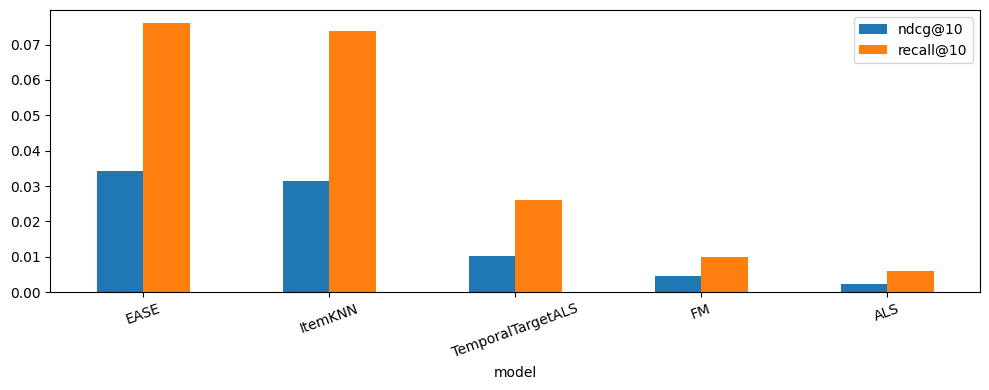

Saved: /content/drive/MyDrive/goodreads_recsys/outputs/validation_results.csv
Saved: /content/drive/MyDrive/goodreads_recsys/outputs/test_results.csv


In [8]:
train_val = pd.concat([train, val], ignore_index=True)
test_rows = []
for name, params in best.items():
    started = time.perf_counter()
    fitted = train_model(name, params, train_val)
    scores = evaluate(fitted, train_val, test, users=selected_users)
    elapsed = time.perf_counter() - started
    test_rows.append({
        'model': name, 'params': params,
        **scores, 'seconds': round(elapsed, 2),
    })
    print(name, scores, f'{elapsed:.1f} sec', flush=True)

results = pd.DataFrame(test_rows).sort_values('ndcg@10', ascending=False)
assert len(results) == 5
assert results[['ndcg@10', 'recall@10']].notna().all().all()
assert results.users.nunique() == 1
output_dir = project_dir / 'outputs'
output_dir.mkdir(exist_ok=True)
validation_results.assign(
    params=validation_results.params.map(json.dumps)
).to_csv(output_dir / 'validation_results.csv', index=False)
results.assign(params=results.params.map(json.dumps)).to_csv(
    output_dir / 'test_results.csv', index=False
)
display(results)
results.set_index('model')[['ndcg@10', 'recall@10']].plot.bar(
    figsize=(10, 4), rot=20, ylim=(0, None)
)
plt.tight_layout()
plt.show()
print('Saved:', output_dir / 'validation_results.csv')
print('Saved:', output_dir / 'test_results.csv')

## Выводы

Лучшие результаты показали EASE (NDCG@10 = 0.0343, Recall@10 = 0.076) и ItemKNN (0.0314 и 0.074). Разница между ними небольшая, поэтому можно сказать, что на этих данных оба метода работают примерно одинаково хорошо а более сложные модели не смогли их обойти.

Обычная ALS показала худший результат среди всех моделей: NDCG@10 = 0.0023, Recall@10 = 0.006. Мб ей не хватило данных для качественного обучения пользовательских и книжных факторов или мы прогадали с гиперпараметрами.

TemporalTargetALS оказалась заметно лучше обычной ALS: NDCG@10 выросла с 0.0023 до 0.0101, а Recall@10 — с 0.006 до 0.026. то есть изменение целевого сигнала с учётом времени действительно помогло в рамках проведённого эксперимента, но даже после этого модель уступает EASE и ItemKNN.

FM с метаданными книг получила NDCG@10 = 0.0045 и Recall@10 = 0.010.

В итоге на выбранной выборке лучше всего сработали EASE и ItemKNN. Временная модификация ALS улучшила результаты базовой модели, но не настолько сильно чтобы догнать их